#FMQI

In [128]:
! pip install --quiet qiskit
! pip install --quiet pylatexenc
! pip install --quiet qiskit-aer

# ! pip install --quiet

In [129]:
! pip install --quiet h5py
import h5py


In [130]:
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit

qr = QuantumRegister(7, 'q')  # 6 address + 1 color
cr = ClassicalRegister(7, 'c')
qc = QuantumCircuit(qr, cr)


In [131]:
print("Total qubits:", qc.num_qubits)
print("Qubits in register:", qc.qregs[0])


Total qubits: 7
Qubits in register: QuantumRegister(7, 'q')


In [132]:
import h5py
import numpy as np
import ast  # To safely parse string tuples

# Load the data
with h5py.File('../../data/raw/5x64x64_training_with_morphology.hdf5', 'r') as f:
    dataset_name = list(f.keys())[0]
    raw_data = f[dataset_name][:]  # dtype is probably |S... (byte strings)

# Convert bytes -> string -> tuple -> extract x value (or any component)
def parse_tuple(s):
    s = s.decode() if isinstance(s, bytes) else s  # decode if bytes
    tup = ast.literal_eval(s)  # safely parse the string as a tuple
    return float(tup[0])  # use x component; change to [1] or [2] for y/z

# Apply parsing to all elements
flat_data = np.array([parse_tuple(s) for s in raw_data], dtype=np.float32)

# Reshape to 64x64 images
num_images = flat_data.size // (64 * 64)
usable_data = flat_data[:num_images * 64 * 64]
data = usable_data.reshape(num_images, 64, 64)
print("Reshaped data:", data.shape)  # (49, 64, 64)

# Downsample to 8x8 using block averaging
def downsample_8x(data):
    return data.reshape(data.shape[0], 8, 8, 8, 8).mean(axis=(3, 4))

downsampled_data = downsample_8x(data)
print("Downsampled shape:", downsampled_data.shape)

# Save result
with h5py.File('../../data/raw/49x8x8_downsampled.h5', 'w') as f:
    f.create_dataset('downsampled', data=downsampled_data)

print("Saved to 49x8x8_downsampled.h5 ✅")

Reshaped data: (49, 64, 64)
Downsampled shape: (49, 8, 8)
Saved to 49x8x8_downsampled.h5 ✅


In [133]:
with h5py.File('../../data/raw/49x8x8_downsampled.h5', 'r') as f:
    # Print dataset keys to see what's inside
    print("Keys:", list(f.keys()))
    
    # Suppose the data is stored under the key 'images' or similar
    data = f['downsampled'][:]  # Replace 'images' with the actual key you find


Keys: ['downsampled']


In [134]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit import transpile, QuantumRegister
from qiskit_aer import Aer
import numpy as np
import random
import keras
from keras.models import Sequential
from keras.layers import Dense, Activation
from keras.datasets import mnist
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, mutual_info_score, r2_score
from qiskit.circuit.library.standard_gates import RYGate, RYYGate
import cv2
import pandas as pd

In [135]:
def hadamard(circ, n):
  for i in n:
    circ.h(i)

In [136]:
def change(state, new_state):
    c = []
    for i in range(len(state)):
        if state[i] != new_state[i]:
            c.append(i)
    print(f"C value as per the change is {c}")
    return np.array(c, dtype=int)  # Ensure output is integer array


In [137]:
def binary(circ, state, new_state):
    c = change(state, new_state)
    print(f"The value of c is {c}")
    if len(c) > 0:
        circ.x(c.tolist())  # ✅ Convert NumPy array to list

def reset_binary(circ, state, new_state):
    # Reverse of binary flip
    c = change(state, new_state)
    if len(c) > 0:
        circ.x(c.tolist())



In [138]:
def cnri(circ, n, t, theta):
  controls = len(n)
  cry = RYGate(2*theta).control(controls)
  aux = np.append(n, t).tolist()
  print(f'aux value is {aux}')
  circ.append(cry, aux)

def frqi(circ, n, t, angles):
    hadamard(circ, n)
    prev_state = '000000'  # initial state

    for j, angle in enumerate(angles):
        curr_state = '{0:06b}'.format(j)
        if j != 0:
            binary(circ, prev_state, curr_state)    # flip qubits for new state
        cnri(circ, n, t, angle)                      # apply controlled rotation
        if j != len(angles) - 1:
            reset_binary(circ, prev_state, curr_state)  # undo flips before next
        prev_state = curr_state



Image shape: (49, 8, 8)
Angles (first 10): [1.1981778  1.1428102  1.2130165  1.0444397  0.9964814  1.0295781
 1.0670699  0.93260074 0.8580082  0.8961975 ]
Angles min: 0.0
Angles max: 1.5707964
Min pixel value: 159425.3
Max pixel value: 180690.31
Normalized pixels: [1.         1.         1.         1.         1.         1.
 1.         1.         1.         1.         1.         1.
 1.         1.         1.         1.         1.         1.
 0.47266012 0.6394658  0.79914707 0.11185625 0.         0.2059339
 0.09399535 1.         1.         1.         1.         1.
 1.         1.         1.         1.         1.         1.
 1.         1.         1.         1.         1.         1.
 1.         1.         1.         1.         1.         1.
 1.         1.         1.         1.         1.         1.
 1.         1.         1.         1.         1.         1.
 1.         1.         1.         1.        ]
Angles: [1.5707964  1.5707964  1.5707964  1.5707964  1.5707964  1.5707964
 1.5707964  1.5707

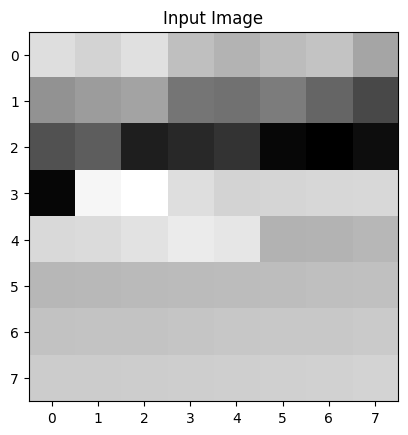

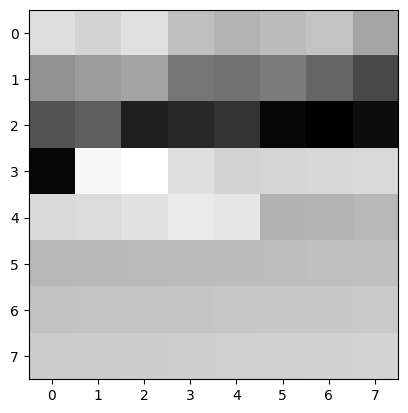

In [139]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

# Load the HDF5 file and extract images
with h5py.File('../../data/raw/49x8x8_downsampled.h5', 'r') as f:
    images = f['downsampled'][:]  # Use the actual key name if it's different

# Check shape: should be (49, 8, 8)
print("Image shape:", images.shape)

# Flatten each 8x8 image to a 64-length vector
pixel_values = images.reshape(images.shape[0], -1)  # (49, 64)

# Select the first image for encoding
img = pixel_values[0]

# Check min and max of the first image to confirm
min_val = np.min(img)
max_val = np.max(img)
# Correct normalization and angle calculation here:
normalized_pixels = (img - min_val) / (max_val - min_val)
normalized_pixels = np.clip(normalized_pixels, 0, 1)

# Apply square root before arcsin (this is key for FRQI)
angles = np.arcsin(np.sqrt(normalized_pixels))
print("Angles (first 10):", angles[:10])
print("Angles min:", np.min(angles))
print("Angles max:", np.max(angles))
print("Min pixel value:", min_val)
print("Max pixel value:", max_val)

# Normalize pixel intensities to [0,1]
normalized_pixels = (img - min_val) / (max_val - min_val)

# Optional: adjust contrast (keep this if needed)
contrast_factor = 4.0
normalized_pixels = normalized_pixels * contrast_factor

# Clip values to [0, 1] before applying arcsin
normalized_pixels = np.clip(normalized_pixels, 0, 1)
normalized_pixels = normalized_pixels[:64]  # ensure exactly 64 pixels

# Convert to angles for FRQI
angles = np.arcsin(normalized_pixels)

print("Normalized pixels:", normalized_pixels)
print("Angles:", angles)


# Show the first image for verification
plt.imshow(images[0], cmap='gray')
plt.title("Input Image")
plt.show()

# Reshape image for quantum encoding
pixel_values = images.reshape(images.shape[0], 64)  # shape: (49, 64)

# Normalize to [0, 1] using real max value
# Normalize to [0, 1] based on full range
min_val = np.min(pixel_values)
max_val = np.max(pixel_values)





plt.imshow(images[0, :], cmap='gray')

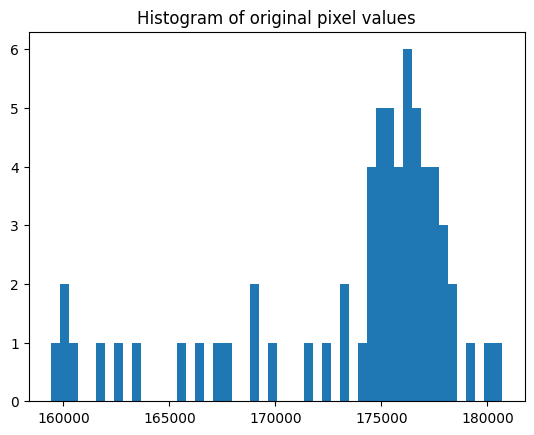

In [140]:
import matplotlib.pyplot as plt
plt.hist(img, bins=50)
plt.title("Histogram of original pixel values")
plt.show()


In [141]:
print("Normalized pixels min:", normalized_pixels.min())
print("Normalized pixels max:", normalized_pixels.max())


Normalized pixels min: 0.0
Normalized pixels max: 1.0


In [142]:
print("min_val =", np.min(pixel_values))
print("max_val =", np.max(pixel_values))
print("max_val - min_val =", np.max(pixel_values) - np.min(pixel_values))





min_val = -206255.28
max_val = 206255.61
max_val - min_val = 412510.88


In [143]:
print(qc.qregs[0])


QuantumRegister(7, 'q')


In [144]:
normalized_pixels = pixel_values/255.0
# Ensure values are in [-1, 1] before arcsin
normalized_pixels = np.clip(normalized_pixels, 0, 1)
normalized_pixels = normalized_pixels[:64]  # ensure exactly 64 pixels

# Encode first image as angles using arcsin
angles = np.arcsin(normalized_pixels[0])


In [145]:
qr = QuantumRegister(7, 'q')
cr = ClassicalRegister(7, 'c')
qc = QuantumCircuit(qr, cr)
frqi(qc, [0, 1, 2, 3, 4, 5], 6, angles)

aux value is [0, 1, 2, 3, 4, 5, 6]
C value as per the change is []
C value as per the change is [5]
The value of c is [5]
aux value is [0, 1, 2, 3, 4, 5, 6]
C value as per the change is [5]
C value as per the change is [4, 5]
The value of c is [4 5]
aux value is [0, 1, 2, 3, 4, 5, 6]
C value as per the change is [4, 5]
C value as per the change is [5]
The value of c is [5]
aux value is [0, 1, 2, 3, 4, 5, 6]
C value as per the change is [5]
C value as per the change is [3, 4, 5]
The value of c is [3 4 5]
aux value is [0, 1, 2, 3, 4, 5, 6]
C value as per the change is [3, 4, 5]
C value as per the change is [5]
The value of c is [5]
aux value is [0, 1, 2, 3, 4, 5, 6]
C value as per the change is [5]
C value as per the change is [4, 5]
The value of c is [4 5]
aux value is [0, 1, 2, 3, 4, 5, 6]
C value as per the change is [4, 5]
C value as per the change is [5]
The value of c is [5]
aux value is [0, 1, 2, 3, 4, 5, 6]
C value as per the change is [5]
C value as per the change is [2, 3, 4, 5

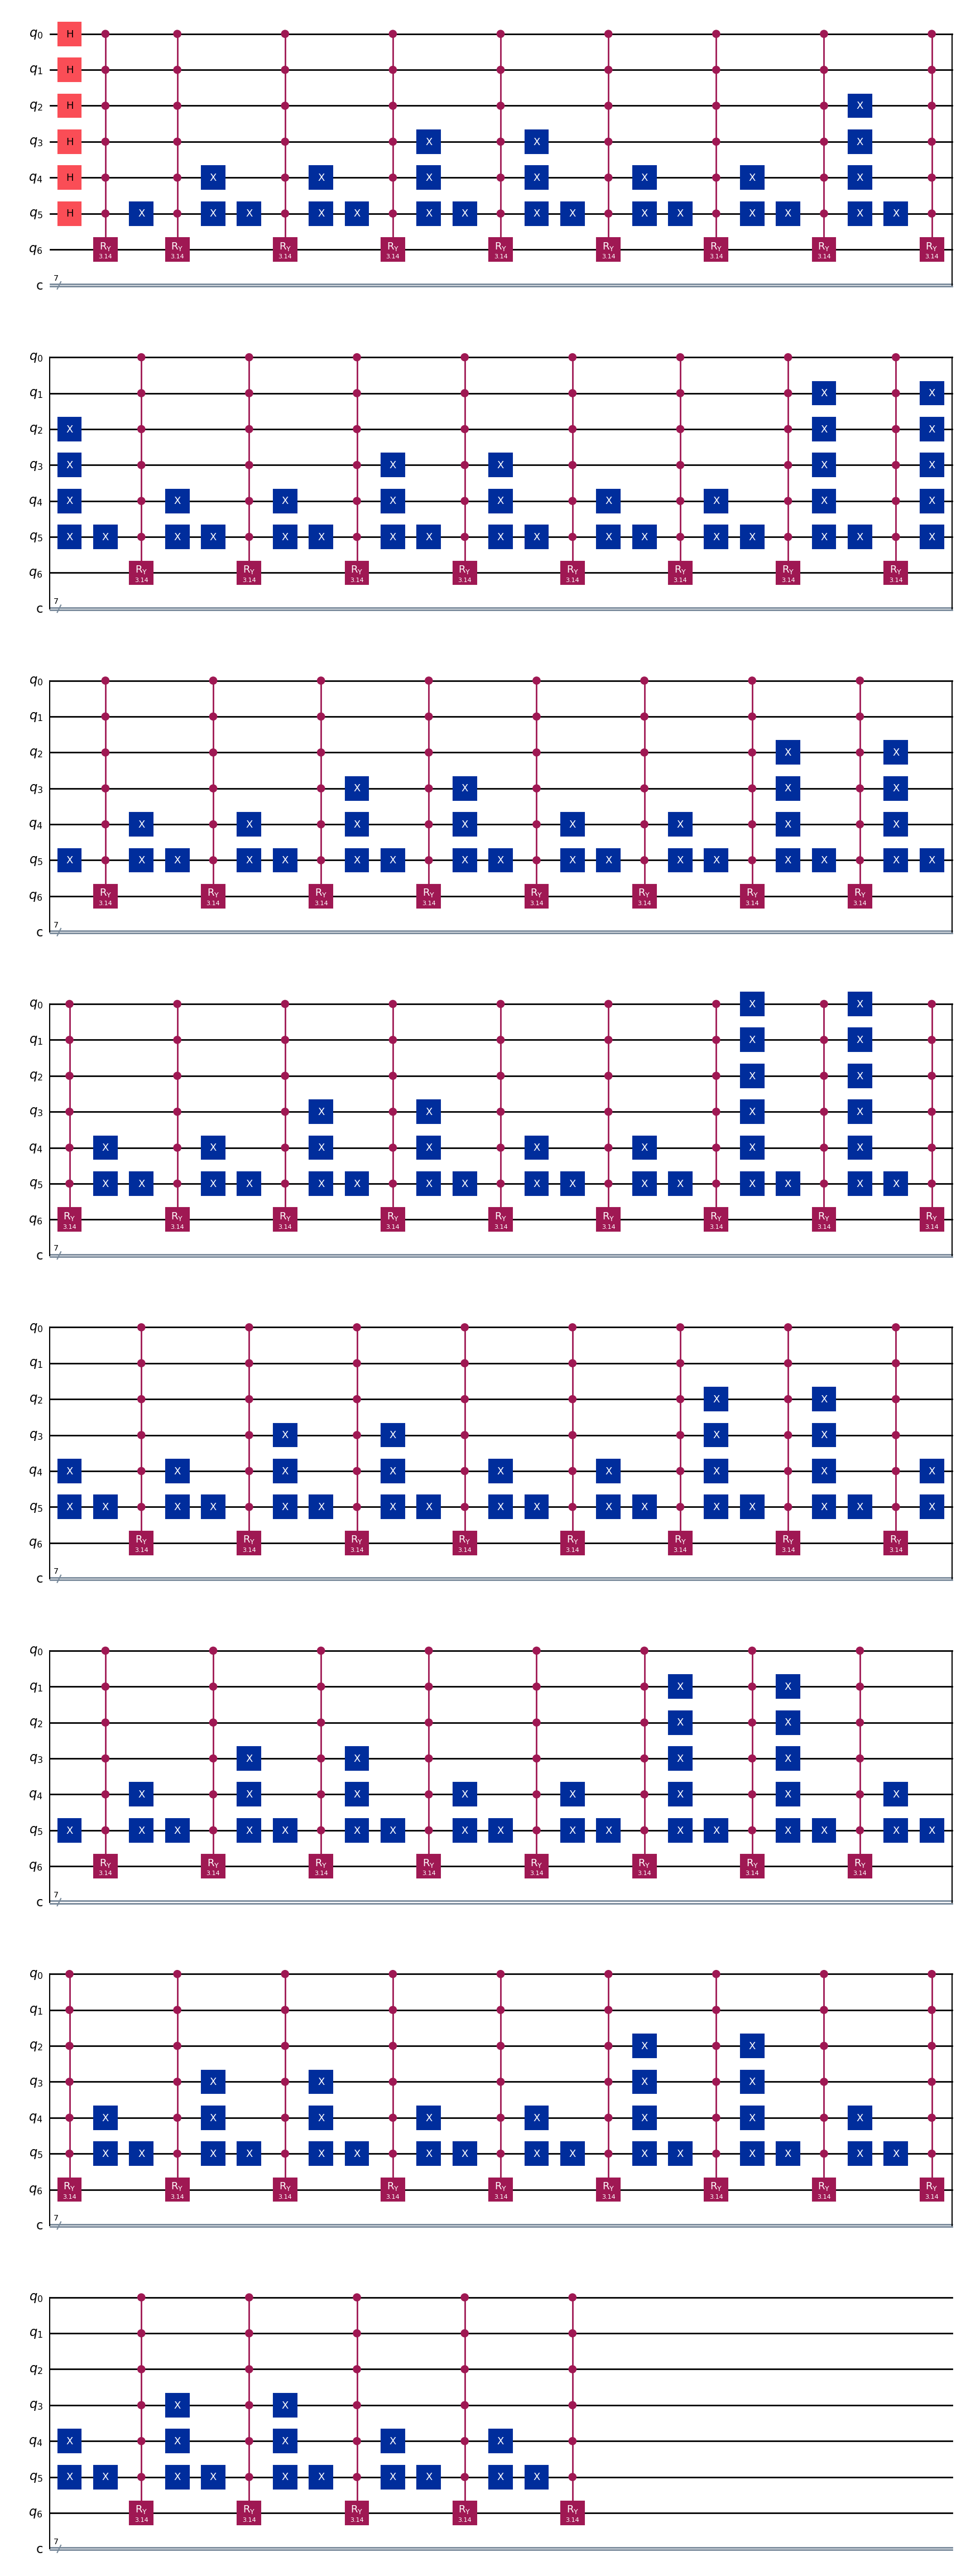

In [146]:
qc.draw(output='mpl')

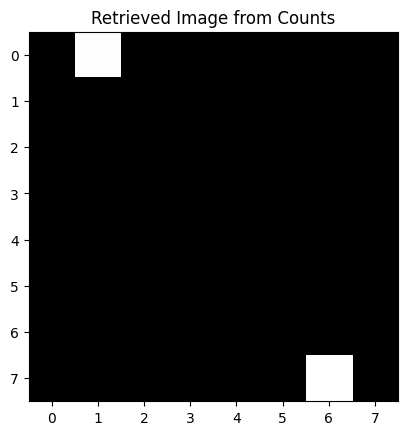

In [147]:
qc.measure([0,1,2,3,4,5,6], [0,1,2,3,4,5,6])

simulator = Aer.get_backend('aer_simulator')
transpiled_circuit = transpile(qc, simulator)
result = simulator.run(transpiled_circuit, shots=10000).result()
counts = result.get_counts()

# Now decode counts to image
retrieve_image = []
shots = 10000
N = 64
for i in range(N):
    addr = format(i, '06b')
    addr_rev = addr[::-1]
    prob = 0
    for bitstring, count in counts.items():
        if len(bitstring) != 7:
            continue
        if bitstring[0] != '1':
            continue
        if bitstring[1:] == addr_rev:
            prob += count / shots
    corrected_prob = prob * N
    intensity = np.sqrt(corrected_prob) * 255.0
    retrieve_image.append(intensity)

retrieve_image = np.array(retrieve_image)
retrieve_image = np.clip(retrieve_image, 0, 255).astype(np.uint8)
retrieve_image = retrieve_image.reshape((8, 8))

import matplotlib.pyplot as plt
plt.imshow(retrieve_image, cmap='gray', vmin=0, vmax=255)
plt.title("Retrieved Image from Counts")
plt.show()


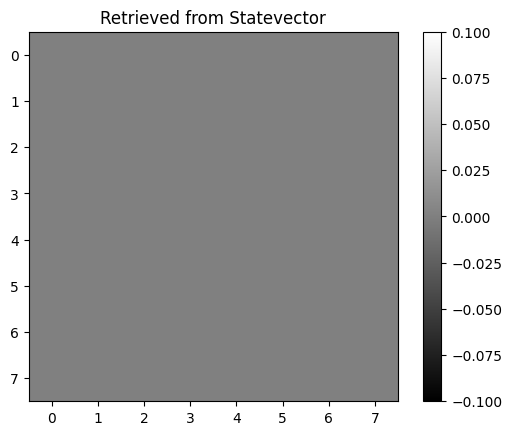

{'0010101': 132, '0101101': 139, '0110011': 174, '0000100': 171, '0111010': 133, '0100110': 148, '0001111': 151, '0101010': 155, '0110110': 147, '0000001': 172, '0010000': 154, '0000011': 139, '0101100': 173, '0110100': 155, '0011000': 161, '0011011': 163, '1011111': 173, '0111101': 178, '0001100': 152, '0100011': 156, '0100010': 156, '0111110': 142, '0001011': 156, '0010100': 129, '0101001': 155, '0000111': 166, '0110000': 164, '0011100': 163, '0011001': 170, '0101011': 145, '0000010': 164, '0110101': 162, '0101110': 147, '0110010': 170, '0000101': 175, '0101000': 166, '0001001': 152, '0000000': 152, '0110111': 167, '0111001': 160, '0011010': 156, '0001101': 156, '0100100': 157, '0111100': 183, '0111000': 174, '0000110': 136, '0110001': 169, '0101111': 183, '0111111': 136, '0001010': 138, '0100001': 158, '0010011': 158, '0010111': 140, '0010110': 126, '0001110': 164, '0111011': 150, '0100101': 135, '0010001': 166, '0100111': 147, '1100000': 154, '0011110': 146, '0011101': 148, '000100

In [148]:
simulator = Aer.get_backend('aer_simulator')
transpiled_circuit = transpile(qc, backend=simulator)
simulator = Aer.get_backend('aer_simulator')
qc.save_statevector()
result = simulator.run(transpile(qc, simulator)).result()
statevector = result.get_statevector()
statevector = np.asarray(statevector)  # ✅ Fix deprecated access

retrieved = []
for i in range(64):
    basis_index = 64 + i  # color qubit (MSB) = 1
    amplitude = statevector[basis_index]
    intensity = abs(amplitude) ** 2
    retrieved.append(np.sqrt(intensity) * 255.0)

retrieved_image = np.array(retrieved).reshape((8, 8))
plt.imshow(retrieved_image, cmap='gray')
plt.title("Retrieved from Statevector")
plt.colorbar()
plt.show()


print(counts)


aux value is [0, 1, 2, 3, 4, 5, 6]
C value as per the change is []
C value as per the change is [5]
The value of c is [5]
aux value is [0, 1, 2, 3, 4, 5, 6]
C value as per the change is [5]
C value as per the change is [4, 5]
The value of c is [4 5]
aux value is [0, 1, 2, 3, 4, 5, 6]
C value as per the change is [4, 5]
C value as per the change is [5]
The value of c is [5]
aux value is [0, 1, 2, 3, 4, 5, 6]
C value as per the change is [5]
C value as per the change is [3, 4, 5]
The value of c is [3 4 5]
aux value is [0, 1, 2, 3, 4, 5, 6]
C value as per the change is [3, 4, 5]
C value as per the change is [5]
The value of c is [5]
aux value is [0, 1, 2, 3, 4, 5, 6]
C value as per the change is [5]
C value as per the change is [4, 5]
The value of c is [4 5]
aux value is [0, 1, 2, 3, 4, 5, 6]
C value as per the change is [4, 5]
C value as per the change is [5]
The value of c is [5]
aux value is [0, 1, 2, 3, 4, 5, 6]
C value as per the change is [5]
C value as per the change is [2, 3, 4, 5

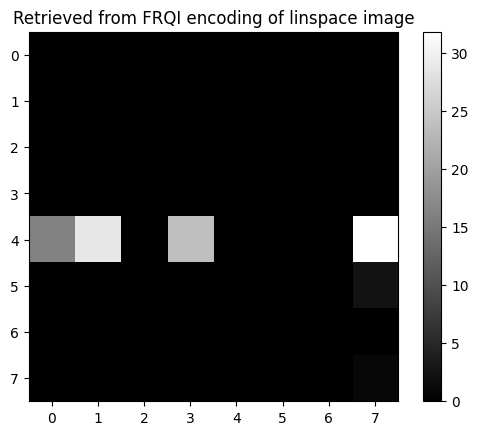

In [149]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import Aer
from qiskit.visualization import plot_state_city
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Generate simple test image values
normalized_pixels = np.linspace(0, 1, 64)
angles = np.arcsin(normalized_pixels)  # FRQI uses θ = arcsin(intensity)

# Step 2: Encode into FRQI circuit
qc = QuantumCircuit(7)  # 6 address qubits + 1 color qubit
frqi(qc, list(range(6)), 6, angles)

# Step 3: Simulate
qc.save_statevector()
sim = Aer.get_backend('aer_simulator')
result = sim.run(transpile(qc, sim)).result()
statevector = np.asarray(result.get_statevector())

# Step 4: Decode image
retrieved = []
for i in range(64):
    basis_index = 64 + i  # MSB = 1 for color qubit
    amplitude = statevector[basis_index]
    intensity = abs(amplitude)**2
    retrieved.append(np.sqrt(intensity) * 255.0)

retrieved_image = np.array(retrieved).reshape((8, 8))

# Step 5: Plot result
plt.imshow(retrieved_image, cmap='gray')
plt.title("Retrieved from FRQI encoding of linspace image")
plt.colorbar()
plt.show()


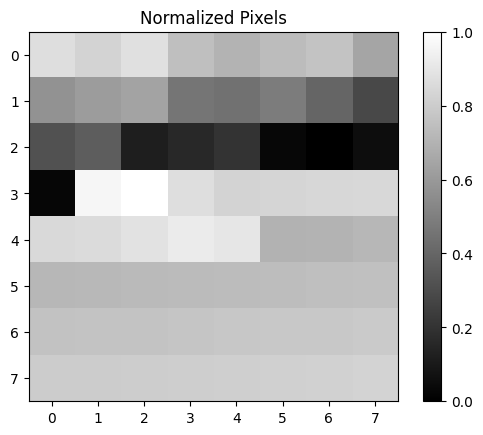

Angles min: 0.0
Angles max: 1.5707964


In [150]:
min_val = np.min(img)
max_val = np.max(img)

if max_val > min_val:
    normalized_pixels = (img - min_val) / (max_val - min_val)
else:
    print("Warning: max and min pixel values are equal; normalization is invalid.")
    normalized_pixels = np.zeros_like(img)


import matplotlib.pyplot as plt
plt.imshow(normalized_pixels.reshape(8,8), cmap='gray')
plt.title("Normalized Pixels")
plt.colorbar()
plt.show()
normalized_pixels = normalized_pixels[:64]

angles = np.arcsin(normalized_pixels)
print("Angles min:", np.min(angles))
print("Angles max:", np.max(angles))


In [151]:
def change(state, new_state):
    c = []
    for i in range(len(state)):
        if state[i] != new_state[i]:
            c.append(i)
    print(f"change(): flipping qubits at indices {c} from state {state} to {new_state}")
    return np.array(c, dtype=int)

def binary(circ, state, new_state):
    c = change(state, new_state)
    if len(c) > 0:
        print(f"binary(): Applying X gates to qubits {c.tolist()}")
        circ.x(c.tolist())

def reset_binary(circ, state, new_state):
    c = change(state, new_state)
    if len(c) > 0:
        print(f"reset_binary(): Applying X gates to qubits {c.tolist()} to undo flips")
        circ.x(c.tolist())


In [152]:
for i in range(64):
    s = format(i, '06b')
    bitstring = '1' + s
    bitstring_rev = bitstring[::-1]

    prob = counts.get(bitstring_rev, 0) / shots
    if prob > 0:
        print(f"{bitstring_rev} → prob: {prob:.6f}")


0000001 → prob: 0.017200
0100001 → prob: 0.015800
0010001 → prob: 0.016600
0110001 → prob: 0.016900
0001001 → prob: 0.015200
0101001 → prob: 0.015500
0011001 → prob: 0.017000
0111001 → prob: 0.016000
0000101 → prob: 0.017500
0100101 → prob: 0.013500
0010101 → prob: 0.013200
0110101 → prob: 0.016200
0001101 → prob: 0.015600
0101101 → prob: 0.013900
0011101 → prob: 0.014800
0111101 → prob: 0.017800
0000011 → prob: 0.013900
0100011 → prob: 0.015600
0010011 → prob: 0.015800
0110011 → prob: 0.017400
0001011 → prob: 0.015600
0101011 → prob: 0.014500
0011011 → prob: 0.016300
0111011 → prob: 0.015000
0000111 → prob: 0.016600
0100111 → prob: 0.014700
0010111 → prob: 0.014000
0110111 → prob: 0.016700
0001111 → prob: 0.015100
0101111 → prob: 0.018300
1011111 → prob: 0.017300
0111111 → prob: 0.013600


In [153]:
print(qc.qregs[0])  # shows your quantum register and qubit order


QuantumRegister(7, 'q')


Pixel 0: prob=0.000000, corrected=0.000000
Pixel 1: prob=0.015400, corrected=0.985600
Pixel 2: prob=0.000000, corrected=0.000000
Pixel 3: prob=0.000000, corrected=0.000000
Pixel 4: prob=0.000000, corrected=0.000000
Pixel 5: prob=0.000000, corrected=0.000000
Pixel 6: prob=0.000000, corrected=0.000000
Pixel 7: prob=0.000000, corrected=0.000000
Pixel 8: prob=0.000000, corrected=0.000000
Pixel 9: prob=0.000000, corrected=0.000000
Pixel 10: prob=0.000000, corrected=0.000000
Pixel 11: prob=0.000000, corrected=0.000000
Pixel 12: prob=0.000000, corrected=0.000000
Pixel 13: prob=0.000000, corrected=0.000000
Pixel 14: prob=0.000000, corrected=0.000000
Pixel 15: prob=0.000000, corrected=0.000000
Pixel 16: prob=0.000000, corrected=0.000000
Pixel 17: prob=0.000000, corrected=0.000000
Pixel 18: prob=0.000000, corrected=0.000000
Pixel 19: prob=0.000000, corrected=0.000000
Pixel 20: prob=0.000000, corrected=0.000000
Pixel 21: prob=0.000000, corrected=0.000000
Pixel 22: prob=0.000000, corrected=0.00000

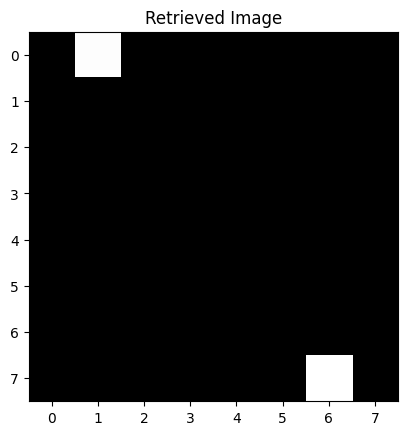

In [154]:
retrieve_image = []

shots = 10000  # Same as your circuit shots

for i in range(64):
    addr = format(i, '06b')
    addr_rev = addr[::-1]
    prob = 0
    for bitstring, count in counts.items():
        if len(bitstring) != 7:
            continue
        if bitstring[0] != '1':
            continue
        if bitstring[1:] == addr_rev:
            prob += count / shots

    # Apply correction factor: probabilities in FRQI are divided across 64 states
    corrected_prob = prob * 64
    print(f"Pixel {i}: prob={prob:.6f}, corrected={prob*64:.6f}")
    intensity = np.sqrt(prob * 64) * 255.0
    retrieve_image.append(intensity)


# Convert to numpy array and reshape
retrieve_image = np.array(retrieve_image)
retrieve_image = np.clip(retrieve_image, 0, 255).astype(int)
retrieve_image = retrieve_image.reshape((8, 8))


import matplotlib.pyplot as plt
plt.imshow(retrieve_image, cmap='gray', vmin=0, vmax=255)
plt.title("Retrieved Image")
plt.show()


#NEQR

In [155]:
! pip install --quiet qiskit
! pip install --quiet pylatexenc
! pip install --quiet qiskit-aer

In [156]:
#Importing Necessary Libraries

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit import transpile, QuantumRegister
from qiskit_aer import Aer
import numpy as np
import qiskit
import random
import keras
from keras.models import Sequential
from keras.layers import Dense, Activation
from keras.datasets import mnist
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, mutual_info_score, r2_score
from qiskit.circuit.library.standard_gates import RYGate, RYYGate, MCXGate
import cv2
import pandas as pd

[[136 132  26 221 176 254  43  13]
 [177 205  24 207 101 182 155  34]
 [228   5  55 157 150  67  50 229]
 [203 121 203 152 232 149 107 154]
 [223   1   0 150 255 161 221 183]
 [141  14  33  46 123 195 228 198]
 [153  92  75 205 222 192  60  48]
 [135 115  72 235 109  95 131   5]]


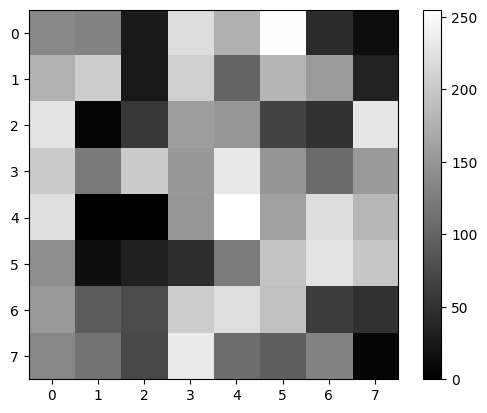

In [157]:
import numpy as np

# Generate an 8x8 array with random values between 0 and 255 (inclusive)
random_array = np.random.randint(0, 256, size=(8,8))

# Visualization of the random array generated
print(random_array)
plt.imshow(random_array, cmap='gray')
plt.colorbar()
plt.show()



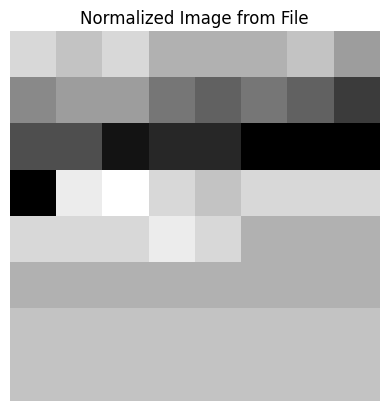

In [158]:
# Normalize pixel values to 0–255
images = data
images = (images - np.min(images)) / (np.max(images) - np.min(images)) * 255
images = images.astype(np.uint8)

# Preview an image
import matplotlib.pyplot as plt
plt.imshow(images[0], cmap='gray')
plt.title("Normalized Image from File")
plt.axis('off')
plt.show()


Data shape: (49, 8, 8)


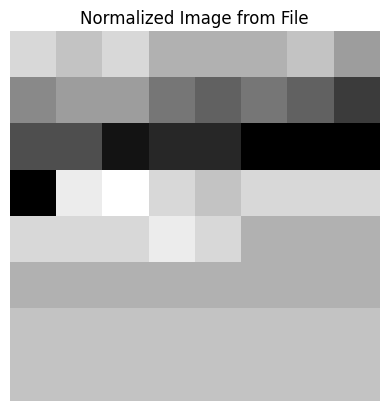

In [159]:
import h5py
import numpy as np

# Load the image data
with h5py.File('../../data/raw/49x8x8_downsampled.h5', 'r') as f:
    data = f['downsampled'][:]

print(f"Data shape: {data.shape}")  # Should be (49, 8, 8)

# Normalize pixel values to 0–255
images = data
images = (images - np.min(images)) / (np.max(images) - np.min(images)) * 255
images = images.astype(np.uint8)

# Preview an image
import matplotlib.pyplot as plt
plt.imshow(images[0], cmap='gray')
plt.title("Normalized Image from File")
plt.axis('off')
plt.show()


In [160]:
#Applying Hadamard Gate for qubits used for pixel location
def hadamard(circ, n):
  for i in n:
    circ.h(i)

In [161]:
from os import name
import math

images = np.array([images[5]])
# images = np.array([random_array])

print(images.shape)

# Using qubit properties, we can represent 2**n values using n qubits
n = int(math.log2(images[0].shape[0]))
q = 8


def SetState(qc, position_x, position_y, q, intensity):
  for i in range(n):
    if position_y[i] == '0':
      qc.x(q + i)
  for i in range(n):
    if position_x[i] == '0':
      # print(n, q, i)
      qc.x(q + n + i)

  control_bits = []
  for i in range(2 * n):
    control_bits.append(q+i)

  intensity = intensity[::-1]
  for i in range(len(intensity)):
    if intensity[i] == '1':
      qc.mcx(control_bits, i)

  for i in range(n):
    if position_y[i] == '0':
      qc.x(q + i)
  for i in range(n):
    if position_x[i] == '0':
      qc.x(q + n + i)


  return qc

def neqr(n, q):
  hadamard_gates = []
  qc = QuantumCircuit(2*n+q, 2*n+q)
  for i in range(2*n + q):
    if i >= q:
      hadamard_gates.append(i)
  hadamard(qc, hadamard_gates)
  qc.barrier()
  for i in range(len(images[0])):
    for j in range(len(images[0][0])):
      position_x = bin(i)[2:].zfill(n)
      position_y = bin(j)[2:].zfill(n)
      intensity = bin(int(images[0][i][j]))[2:].zfill(q)
      qc = SetState(qc, position_x, position_y, q, intensity)
      qc.barrier()
  return qc

qc = neqr(n, q)
qc.measure([i for i in range(2*n + q)], [i for i in range(2*n +q)])
# qc.draw(output="mpl")

(1, 8, 8)


In [162]:
simulator = Aer.get_backend('aer_simulator')
transpiled_circuit = transpile(qc, backend=simulator)
result = simulator.run(transpiled_circuit, backend=simulator, shots=1000000)
counts = result.result().get_counts()
print(counts)
print(len(counts))

{'01111011100101': 15553, '10111111100101': 15545, '00011011100101': 15697, '11001011100100': 15559, '01100111100101': 15679, '00100011100101': 15513, '01011111100100': 15787, '10010111100111': 15559, '10000111100110': 15773, '00111011100101': 15535, '00101011100101': 15472, '11100111100010': 15514, '11111111100011': 15569, '10000011100110': 15823, '01101111100101': 15690, '11010011100100': 15697, '11000011100100': 15585, '10101011100101': 15729, '10011111100111': 15666, '10101111100101': 15808, '00001011100101': 15579, '00000011100101': 15653, '00011111100110': 15631, '11101111100010': 15838, '00000111100110': 15629, '01110011100101': 15621, '11011011100100': 15672, '00010011100101': 15719, '10110111100101': 15780, '11110111100010': 15740, '00110111100101': 15802, '11110011100101': 15591, '00111111100101': 15764, '10001111100111': 15455, '11001111100100': 15478, '11100011100101': 15696, '01000011100111': 15485, '10100111100101': 15459, '11101011100010': 15628, '01110111100101': 15606,

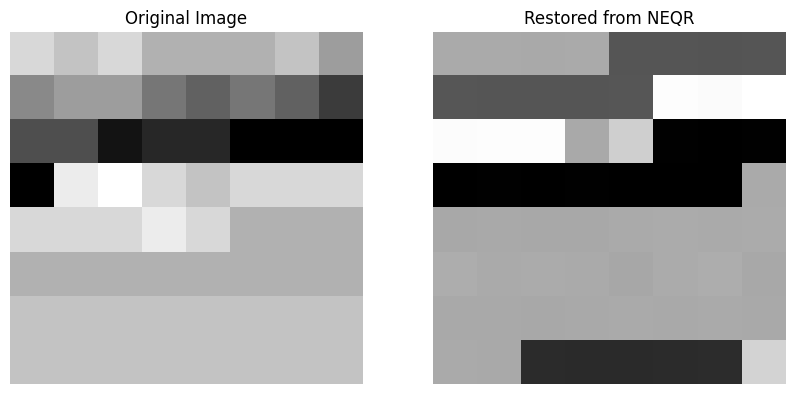

In [163]:
# Normalize and prepare original image
images = data
images = (images - np.min(images)) / (np.max(images) - np.min(images)) * 255
images = images.astype(np.uint8)

original_image = images[0]  # pick the image you encoded

# Create an empty restored image
restored_image = np.zeros((2**n, 2**n))

# Reconstruct image from NEQR measurement results
for bitstring, count in counts.items():
    bitstring = bitstring[::-1]  # reverse due to qiskit's little endian

    intensity_bits = bitstring[:q]
    y_bits = bitstring[q:q+n]
    x_bits = bitstring[q+n:q+2*n]

    intensity = int(intensity_bits, 2)
    y = int(y_bits, 2)
    x = int(x_bits, 2)

    restored_image[x, y] += intensity * count  # accumulate intensity weighted by count

# Normalize restored image
restored_image = restored_image / np.max(restored_image) * 255
restored_image = restored_image.astype(np.uint8)

# Plot both images side by side
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(10, 5))

axs[0].imshow(original_image, cmap='gray')
axs[0].set_title("Original Image")
axs[0].axis('off')

axs[1].imshow(restored_image, cmap='gray')
axs[1].set_title("Restored from NEQR")
axs[1].axis('off')

plt.show()
